# 03 · Benchmark: NASA C-MAPSS FD001 remaining useful life

**Dataset.** *Turbofan Engine Degradation Simulation Data Set* (C-MAPSS), NASA Ames Prognostics Center of Excellence. Subset **FD001**: one operating condition, one fault mode (HPC degradation), 100 training engines run to failure, and 100 test engines cut off at some point before failure. Each row is one engine cycle with 3 operational settings and 21 sensor channels.

> **This is a simulated dataset.** The engines and their degradation were generated with NASA's C-MAPSS simulation software, not recorded from real aircraft. It is the standard benchmark for remaining-useful-life (RUL) prediction, which makes it a fair yardstick for a method, not evidence about real engines.

**Task.** For each test engine, predict how many cycles remain after its last recorded cycle. The official split and the provided `RUL_FD001.txt` ground truth are used as-is.

**Citation.** A. Saxena, K. Goebel, D. Simon, N. Eklund, "Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation," *International Conference on Prognostics and Health Management (PHM08)*, Denver, CO, 2008. Data: A. Saxena and K. Goebel (2008), "Turbofan Engine Degradation Simulation Data Set," NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.

In [1]:
import io, json, sys, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
import plot_style as ps

ps.apply()
SEED, CAP, WINDOW = 42, 125, 10
DATA = ROOT / "data" / "cmapss"              # git-ignored download cache
OUT = ROOT / "results" / "benchmarks" / "cmapss_fd001"
URL = "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"

## 1. Download and load

In [2]:
DATA.mkdir(parents=True, exist_ok=True)
zip_path = DATA / "cmapss.zip"
if not zip_path.exists():
    urllib.request.urlretrieve(URL, zip_path)

COLS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
with zipfile.ZipFile(zip_path) as outer:
    inner_name = next(n for n in outer.namelist() if n.endswith("CMAPSSData.zip"))
    with zipfile.ZipFile(io.BytesIO(outer.read(inner_name))) as z:
        read = lambda name, **kw: pd.read_csv(z.open(name), sep=r"\s+", header=None, **kw)
        train = read("train_FD001.txt", names=COLS)
        test = read("test_FD001.txt", names=COLS)
        rul_true = read("RUL_FD001.txt")[0].values

print(f"train: {train.unit.nunique()} engines, {len(train):,} cycles · test: {test.unit.nunique()} engines, {len(test):,} cycles")
print(f"train engine life: {train.groupby('unit').cycle.max().agg(['min', 'median', 'max']).to_dict()}")
print(f"test true RUL: min {rul_true.min()}, median {np.median(rul_true):.0f}, max {rul_true.max()}")

train: 100 engines, 20,631 cycles · test: 100 engines, 13,096 cycles
train engine life: {'min': 128.0, 'median': 199.0, 'max': 362.0}
test true RUL: min 7, median 86, max 145


## 2. Target: capped RUL

In training, RUL = (engine's last cycle) − (current cycle). Early in life an engine shows no measurable degradation, so a target of "250 cycles left" can't be told apart from "150 cycles left". The usual fix is a piecewise-linear target: RUL is **capped at 125**, meaning "healthy, at least 125 cycles to go", and only counts down once degradation could plausibly be visible.

In [3]:
train["rul"] = (train.groupby("unit").cycle.transform("max") - train.cycle).clip(upper=CAP)

# FD001 has a single operating condition: settings and several sensors are (near-)constant
spread = train[COLS[2:]].std()
SENSORS = [c for c in COLS[5:] if spread[c] > 1e-2]
print("dropped (near-constant):", [c for c in COLS[2:] if c not in SENSORS])
print("kept sensors:", SENSORS)

dropped (near-constant): ['op1', 'op2', 'op3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
kept sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. Features

Single sensor readings are noisy. For each sensor, the features are the current value plus the mean and standard deviation over the **last 10 cycles of the same engine** (only past cycles, so nothing from the future leaks in), plus the cycle count. The test engines get exactly the same features, computed from their own history.

In [4]:
def add_features(d):
    d = d.sort_values(["unit", "cycle"]).copy()
    g = d.groupby("unit")[SENSORS]
    roll = g.rolling(WINDOW, min_periods=1)
    means = roll.mean().reset_index(level=0, drop=True).add_suffix("_mean")
    stds = roll.std().reset_index(level=0, drop=True).fillna(0).add_suffix("_std")
    return pd.concat([d, means, stds], axis=1)

tr = add_features(train)
te_all = add_features(test)
te = te_all.groupby("unit").tail(1).sort_values("unit")      # last observed cycle per test engine
assert len(te) == len(rul_true) == 100

FEATS = ["cycle"] + SENSORS + [f"{s}_mean" for s in SENSORS] + [f"{s}_std" for s in SENSORS]
print(f"{len(FEATS)} features")

43 features


## 4. Models and scoring

- **Baseline**: always predict the mean capped RUL of the training set.
- **Linear regression** on the raw current sensor values (no history window): a simple, common reference.
- **Random Forest** and **gradient boosting** (`HistGradientBoostingRegressor`) on the windowed features.

Metrics:
- **RMSE** in cycles.
- The **NASA scoring function** from the PHM08 challenge. With $d = \hat{y} - y$, $s = \sum_i \big(e^{-d_i/13} - 1\big)$ for early predictions ($d<0$) and $\big(e^{d_i/10} - 1\big)$ for late ones. Lower is better, and it punishes late predictions (an engine failing before you expected it to) harder than early ones.

Both metrics are reported against the official true RUL. RMSE is also reported against the true RUL capped at 125, which is how much of the literature reports FD001.

Hyperparameters are fixed up front. A 5-fold cross-validation over *training engines* (`GroupKFold` by unit) gives a check that doesn't touch the test set.

In [5]:
def nasa_score(y, yhat):
    d = np.asarray(yhat) - np.asarray(y)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

rmse = lambda y, yhat: float(np.sqrt(np.mean((np.asarray(y) - np.asarray(yhat)) ** 2)))

MODELS = {
    "Baseline (mean RUL)": (None, None),
    "Linear regression (raw sensors)": (lambda: make_pipeline(StandardScaler(), LinearRegression()), SENSORS),
    "Random Forest": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.3,
                                                     n_jobs=-1, random_state=SEED), FEATS),
    "Gradient boosting": (lambda: HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                                                 random_state=SEED), FEATS),
}

rows, preds = [], {}
gkf = GroupKFold(n_splits=5)
for name, (factory, feats) in MODELS.items():
    if factory is None:
        yhat = np.full(len(te), tr["rul"].mean())
        cv_rmse = np.mean([rmse(tr["rul"].iloc[v], np.full(len(v), tr["rul"].iloc[t].mean()))
                           for t, v in gkf.split(tr, groups=tr["unit"])])
    else:
        cv_rmse = np.mean([rmse(tr["rul"].iloc[v], factory().fit(tr[feats].iloc[t], tr["rul"].iloc[t]).predict(tr[feats].iloc[v]))
                           for t, v in gkf.split(tr, groups=tr["unit"])])
        yhat = factory().fit(tr[feats], tr["rul"]).predict(te[feats])
    yhat = np.clip(yhat, 0, None)
    preds[name] = yhat
    rows.append({"model": name, "cv_rmse_train_engines": round(cv_rmse, 2),
                 "test_rmse": round(rmse(rul_true, yhat), 2),
                 "test_rmse_capped_truth": round(rmse(np.minimum(rul_true, CAP), yhat), 2),
                 "nasa_score": round(nasa_score(rul_true, yhat), 1)})

res = pd.DataFrame(rows).set_index("model")
res

,cv_rmse_train_engines,test_rmse,test_rmse_capped_truth,nasa_score
model,,,,
Baseline (mean RUL),41.67,43.07,41.94,33629.2
Linear regression (raw sensors),21.66,21.90,20.82,1314.0
Random Forest,16.50,19.07,17.89,684.5
Gradient boosting,16.99,20.55,19.45,1072.1


`cv_rmse_train_engines` is measured over *all* cycles of the held-out training engines. The test columns cover only one point per engine (its last observed cycle), so the two are not directly comparable. For reference, published FD001 results range from roughly RMSE 16–18 for classic ML to about 11–13 for deep sequence models (CNN/LSTM), most of them computed against capped truth.

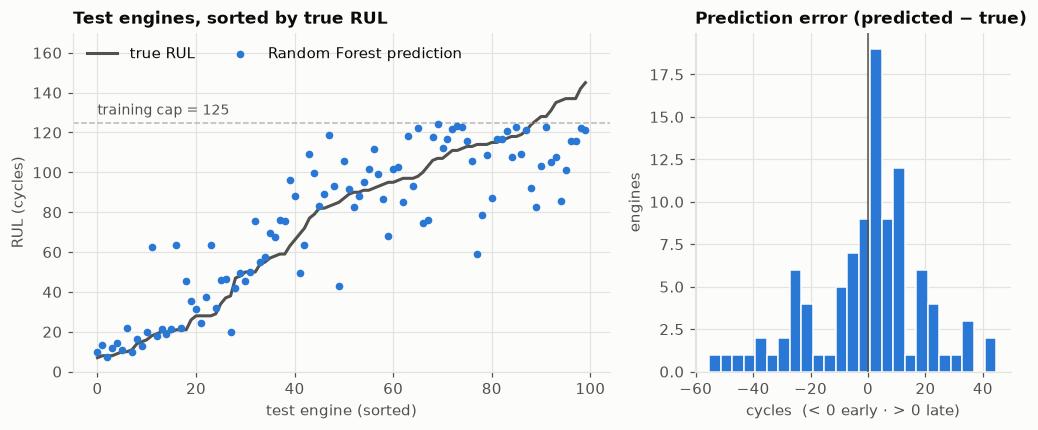

selected by training CV: Random Forest · late predictions: 60 of 100 · errors > 30 cycles: 13


In [6]:
best = res.drop(index="Baseline (mean RUL)")["cv_rmse_train_engines"].idxmin()
order = np.argsort(rul_true)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
ax.plot(np.arange(100), rul_true[order], color=ps.TEXT_2, lw=2, label="true RUL")
ax.scatter(np.arange(100), preds[best][order], s=16, color=ps.SERIES[0], label=f"{best} prediction", zorder=3)
ax.axhline(CAP, color=ps.NEUTRAL, lw=1, ls="--")
ax.text(0, CAP + 4, f"training cap = {CAP}", color=ps.TEXT_2, fontsize=9)
ax.set(title="Test engines, sorted by true RUL", xlabel="test engine (sorted)", ylabel="RUL (cycles)",
       ylim=(0, max(rul_true.max(), preds[best].max()) + 25))
ax.legend(loc="upper left", ncols=2)
ax = axes[1]
err = preds[best] - rul_true
ax.hist(err, bins=25, color=ps.SERIES[0], edgecolor=ps.SURFACE)
ax.axvline(0, color=ps.TEXT_2, lw=1)
ax.set(title="Prediction error (predicted − true)", xlabel="cycles  (< 0 early · > 0 late)", ylabel="engines")
ps.save(fig, OUT / "rul_predictions.png")
print(f"selected by training CV: {best} · late predictions: {(err > 0).sum()} of 100 · "
      f"errors > 30 cycles: {(np.abs(err) > 30).sum()}")

Where do the errors come from? Mean error by true-RUL band (negative = early, positive = late):

In [7]:
band = pd.cut(rul_true, [0, 50, 100, CAP, rul_true.max()], labels=["≤ 50", "51–100", f"101–{CAP}", f"> {CAP}"])
pd.DataFrame({"engines": pd.Series(err).groupby(band, observed=True).size(),
              "mean error": pd.Series(err).groupby(band, observed=True).mean().round(1),
              "errors > 30 cycles": pd.Series(np.abs(err) > 30).groupby(band, observed=True).sum()})

,engines,mean error,errors > 30 cycles
≤ 50,33,6.8,3
51–100,34,5.5,4
101–125,22,-5.5,3
> 125,11,-27.3,3


Two different effects:
- **Healthy engines (true RUL > 125) are under-predicted.** The model was trained to say "at least 125" for them, so it can't tell 125 from 145 cycles left. That is the cost of the cap. It is the *safe* direction, and it's why the capped-truth RMSE is lower.
- **Engines closer to failure are, on average, predicted a few cycles late.** That is the costly direction for maintenance, and the NASA score penalises it. A deployed system would add a safety margin or train with an asymmetric loss.

## 5. Save results

In [8]:
OUT.mkdir(parents=True, exist_ok=True)
summary = {
    "dataset": "NASA C-MAPSS turbofan degradation, subset FD001 — simulated",
    "citation": "A. Saxena, K. Goebel, D. Simon, N. Eklund, 'Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation', PHM08, 2008. Data: NASA Prognostics Data Repository, NASA Ames Research Center.",
    "url": "https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/",
    "task": "remaining useful life at each test engine's last observed cycle; official train/test split and RUL_FD001.txt",
    "train_engines": int(train.unit.nunique()), "test_engines": int(test.unit.nunique()),
    "rul_cap": CAP, "window": WINDOW, "sensors": SENSORS,
    "results": res.reset_index().to_dict("records"),
    "selected": best,
    "figures": ["rul_predictions.png"],
}
(OUT / "metrics.json").write_text(json.dumps(summary, indent=2))
print("saved", sorted(p.name for p in OUT.iterdir()))

saved ['metrics.json', 'rul_predictions.png']


## 6. Takeaways

- **History matters.** Rolling means over the last 10 cycles smooth out sensor noise. The windowed tree models clearly beat linear regression on single readings, which in turn beats the constant baseline by a wide margin.
- **The cap is a modelling choice with a visible cost.** It makes training targets learnable, but healthy engines with a long RUL get under-predicted (safe), and the model is slightly optimistic for engines closer to failure (not safe). The second is the one to fix first, for example with a safety margin or an asymmetric loss.
- **Random Forest vs. gradient boosting.** Both are close. The Random Forest was chosen on training-engine CV and also scores best on the test set here. The gradient boosting settings weren't tuned.
- **Honest limits.** This is one operating condition and one fault mode of a simulator. Real fleets mix operating regimes and fault types (the FD002–FD004 subsets get closer to that), and real sensors drift.